## Part 1: Explore & Split

### Set up

In [47]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, confusion_matrix

### Exercise 1.1

In [48]:
df = pd.read_csv("week10_students.csv")
print(df.shape)

features=["quiz_avg","assignments_avg","attendance_pct"]
print(df[features + ["score"]].corr()["score"].drop("score"))
# quiz_avg is the most useful feature, it has the highest correlation with score

(150, 9)
quiz_avg           0.800726
assignments_avg    0.535983
attendance_pct     0.238118
Name: score, dtype: float64


### Exercise 1.2

In [49]:
X = df[features]
y = df["score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
) 

print(len(X_train),len(X_test))
# 25% of students are hidden from the model so we can test it on data it has never seen. 
# Scoring on the training data would only show how well the model
# memorised those students, not whether it works for a new student.

112 38


## Part 2 · Regression — Predict the Score

### Exercise 2.1 — Train & read the model

In [50]:
model = LinearRegression()
model.fit(X_train, y_train)

for name,coef in zip(features,model.coef_):
    print(f"{name}: {coef:.3f}")
print(f"Intercept: ", round(model.intercept_,3)) 

# One extra quiz point ≈ (coefficient of quiz_avg) extra exam points,
# holding assignments and attendance the same.

quiz_avg: 0.579
assignments_avg: 0.365
attendance_pct: 0.113
Intercept:  -4.428


### Exercise 2.2: Judge it honestly

In [51]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("MAE: ", round(mae,2))
print("R2: ", round(r2,2))

# MAE: on average, the model's predicted score is off by about 3.3 points,
# so a student predicted at 60 probably scored between about 57 and 63.
# R2: the model explains about 89% of why students' scores differ; the other
# ~11% is down to things it can't see (effort on exam day, luck, etc.).

MAE:  3.33
R2:  0.89


### Exercise 2.3: Predict a new student

In [52]:
new_student = pd.DataFrame(
    [[70,75,90]],
    columns=["quiz_avg", "assignments_avg", "attendance_pct"]
)
print(model.predict(new_student))
# My numbers
me = pd.DataFrame([[80,70,90]], columns=features)
print(model.predict(me))

[73.66410989]
[77.63003027]


## Part 3 · Classification — Catch the At-Risk Students

### Exercise 3.1: Build the target and train

In [53]:
df["passed"] = (df["score"] >= 50).astype(int)
print(df["passed"].value_counts())
Xc = df[features]
yc = df["passed"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.25, random_state=42
)
clt = LogisticRegression(max_iter=1000)
clt.fit(Xc_train,yc_train)

passed
1    131
0     19
Name: count, dtype: int64


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


### Exercise 3.2: The accuracy trap

In [54]:
yc_pred = clt.predict(Xc_test)

print("Model accuracy: ", round(accuracy_score(yc_test,yc_pred),3))
print("Lazy baseline: ", round(yc_test.mean(), 3))
print(confusion_matrix(yc_test, yc_pred))

# The two accuracies are identical (0.895), but the model is not useless.
# The lazy baseline predicts "pass" for everyone, so it catches 0 of the 4
# students who failed. Our model correctly flags 3 of those 4 (top row of the
# confusion matrix), at the cost of 3 false alarms (students who passed but
# were flagged). Accuracy hides this because ~89% of students pass, so the
# passing majority dominates the score. The confusion matrix shows the model
# finds at-risk students that the baseline misses entirely.

Model accuracy:  0.895
Lazy baseline:  0.895
[[ 3  1]
 [ 3 31]]


## Part 4 · Feature Engineering

In [56]:
def test_r2(X):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42)
    m = LinearRegression().fit(X_tr, y_tr)
    return r2_score(y_te, m.predict(X_te))
    
# quiz_avg only
r2_quiz = test_r2(df[["quiz_avg"]])

# the 3 features
r2_all = test_r2(df[features])

# all three + program one-hot encoded
X_prog =  pd.get_dummies(df[features + ["program"]], columns=["program"], dtype=int)
r2_prog = test_r2(X_prog)

print(f"1. quiz only:           {r2_quiz:.2f}")   
print(f"2. three numeric:       {r2_all:.2f}")   
print(f"3. + program one-hot:   {r2_prog:.2f}")

1. quiz only:           0.62
2. three numeric:       0.89
3. + program one-hot:   0.88


In [57]:
# Going from quiz_avg alone to all three numeric features helped a lot
# (R2 ~0.62 -> ~0.89): assignments and attendance carry real information
# about the score that quiz_avg alone misses.
# Adding program did not help (~0.89 -> ~0.88, slightly worse): it adds
# information, but not useful information for predicting the score.
# Lesson: more features is not automatically better. A feature must be
# relevant, and irrelevant ones add noise, especially with only 112
# training students.

## Part 5 · Ship a Dashboard

### Set Up

In [58]:
import plotly.express as px

### Exercise 5.1: The story in three charts

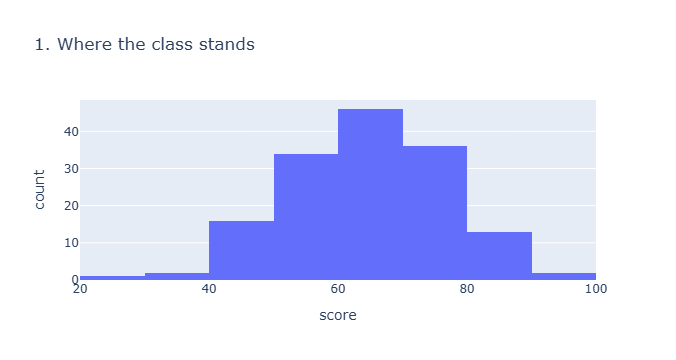

In [60]:
# a. Where the class stands
fig1 = px.histogram(df, x="score", nbins=12, title="1. Where the class stands")
fig1.show()

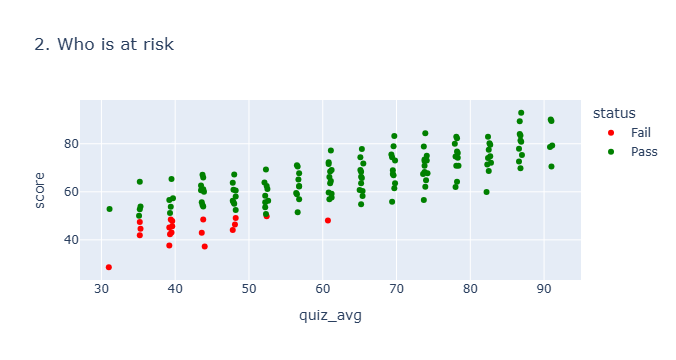

In [66]:
# b. Who is at risk
df["status"] = df["passed"].map({1: "Pass", 0: "Fail"})

fig2 = px.scatter(
    df, x="quiz_avg", y="score", color="status",
    hover_name="name", title="2. Who is at risk",
    color_discrete_map={"Pass": "green", "Fail": "red"}
)
fig2.show()

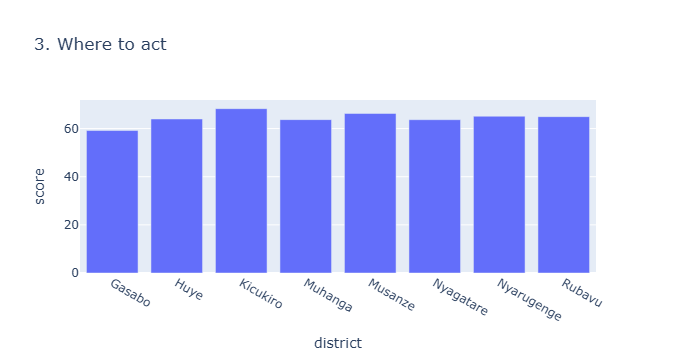

In [68]:
# Where to act
district_avg = df.groupby("district")["score"].mean().reset_index()
fig3 = px.bar(district_avg, x="district", y="score", title="3. Where to act")
fig3.show()

### Exercise 5.2 — Publish it

In [70]:
fig2.write_html("class_dashboard.html")

### One chart, four stories

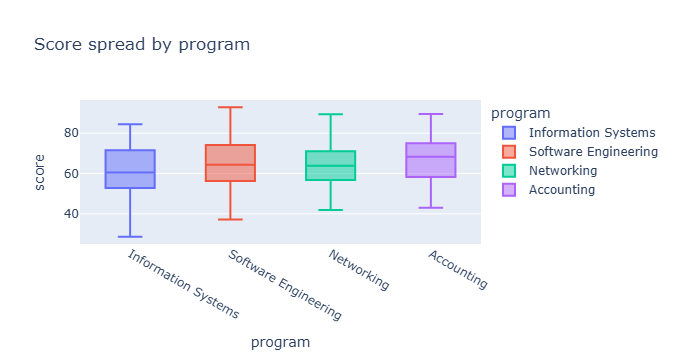

In [71]:
fig4 = px.box(df, x="program", y="score", color="program", title="Score spread by program")
fig4.show()

## Part 6: The model card

1. Purpose

This model predicts a student’s final score (0 to 100) at AUCA from their quiz average, assignment average, and attendance. It is meant to help lecturers spot students who may be heading for a low score early enough to offer support.

2. Data & features

Trained on 112 students (75% of a 150-student dataset), tested on 38 held-out students. Inputs: quiz_avg, assignments_avg, attendance_pct. The target is score. Student names, program, and district were not used as inputs in the final model.

3. Performance (on unseen data)

On the 38 test students, the model’s predictions are off by about 3.3 points on average (MAE). R² is 0.89, meaning the model explains about 89% of why students’ scores differ. In plain terms: a student predicted at 60 most likely scored between 53 and 63.


4. Risks (who could be harmed, and how to use it)

Who could be harmed: a student wrongly predicted to score low could be labelled “weak”, lose opportunities, or be treated with lower expectations. A student wrongly predicted to do well might not get help they needed. The model is trained on one group of 150 students, so it may be less accurate for students unlike that group.

Use it for: an early-warning signal that prompts a conversation or an offer of support, always checked by a human who knows the student.

Do NOT use it for: assigning grades, deciding admissions, scholarships, or discipline, or making decisions about a student without a lecturer’s judgment. The model also shouldn’t be used to judge programs or districts.